# K-Means Clustering: U.S. Traffic Safety & Insurance Costs

**Dataset:** `bad-drivers(2).csv` (provided dataset; 50 U.S. states + Washington, D.C.)  
**Algorithm:** **K-Means clustering** (unsupervised machine learning)  
**Problem:** A national traffic safety agency wants to **group states with similar driving risks and insurance-cost profiles**, then design **one primary safety campaign per group** (e.g., anti-speeding, anti-drunk-driving).  
**Questions:** (1) How many groups make sense? (2) What describes each group? (3) Which campaigns fit each group?

## 1. Import libraries and load the dataset

Put this notebook and `bad-drivers(2).csv` in the **same folder**. The loader also accepts similarly named `bad-drivers*.csv` files (useful if your download adds a suffix).

In [ ]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

RANDOM_STATE = 42
DATA_FILE = Path("bad-drivers(2).csv")

if not DATA_FILE.is_file():
    alternatives = sorted(Path(".").glob("bad-drivers*.csv"))
    if not alternatives:
        raise FileNotFoundError(
            "Place bad-drivers(2).csv in the same folder as this notebook, "
            "or use the bundled ZIP that includes both files."
        )
    DATA_FILE = alternatives[0]

raw = pd.read_csv(DATA_FILE)
print(f"Dataset: {DATA_FILE.name}")
print(f"Observations: {len(raw)} | Columns: {raw.shape[1]}")
display(raw.head())

Dataset: bad-drivers(2).csv
Observations: 51 | Columns: 8


,State,Number of drivers involved in fatal collisions per billion miles,Percentage Of Drivers Involved In Fatal Collisions Who Were Speeding,Percentage Of Drivers Involved In Fatal Collisions Who Were Alcohol-Impaired,Percentage Of Drivers Involved In Fatal Collisions Who Were Not Distracted,Percentage Of Drivers Involved In Fatal Collisions Who Had Not Been Involved In Any Previous Accidents,Car Insurance Premiums ($),Losses incurred by insurance companies for collisions per insured driver ($)
0,Alabama,18.8,39,30,96,80,784.55,145.08
1,Alaska,18.1,41,25,90,94,1053.48,133.93
2,Arizona,18.6,35,28,84,96,899.47,110.35
3,Arkansas,22.4,18,26,94,95,827.34,142.39
4,California,12.0,35,28,91,89,878.41,165.63


## 2. Inspect data quality and interpret the columns

- `State` is an **identifier**, not a feature for K-Means.
- The numerical features represent fatal-collision involvement, proportions of drivers involved in fatal collisions, and insurance costs.
- **Important:** speeding / alcohol / distraction percentages are conditional on **drivers involved in fatal collisions**. They are *not* percentages of all licensed drivers.

In [ ]:
print("Column names:")
for c in raw.columns:
    print(" -", c)

print("\nMissing values by column:")
display(raw.isna().sum().rename("Missing values").to_frame())
print("Duplicated states:", raw["State"].duplicated().sum())
assert raw["State"].notna().all(), "All rows need a state identifier."
assert raw["State"].nunique() == len(raw), "Duplicated state names: review source file."

# Rename to make the notebook easier to read.
rename_map = {
    raw.columns[1]: "fatal_rate",
    raw.columns[2]: "speeding_pct",
    raw.columns[3]: "alcohol_pct",
    raw.columns[4]: "not_distracted_pct",
    raw.columns[5]: "no_prior_accidents_pct",
    raw.columns[6]: "premium_usd",
    raw.columns[7]: "loss_usd",
}
df = raw.rename(columns=rename_map).copy()

# Flip two percentages so larger numbers consistently indicate a potential risk.
# Interpret as complements of the reported categories (may depend on reporting quality).
df["distracted_pct"] = 100 - df["not_distracted_pct"]
df["prior_accidents_pct"] = 100 - df["no_prior_accidents_pct"]

FEATURES = [
    "fatal_rate", "speeding_pct", "alcohol_pct", "distracted_pct",
    "prior_accidents_pct", "premium_usd", "loss_usd"
]
for col in FEATURES:
    df[col] = pd.to_numeric(df[col], errors="coerce")
    if df[col].isna().any():
        print(f"Filling {df[col].isna().sum()} missing values in {col} with its median.")
        df[col] = df[col].fillna(df[col].median())

print("\nSelected K-Means features:", FEATURES)
display(df[FEATURES].describe().round(2))

Column names:
 - State
 - Number of drivers involved in fatal collisions per billion miles
 - Percentage Of Drivers Involved In Fatal Collisions Who Were Speeding
 - Percentage Of Drivers Involved In Fatal Collisions Who Were Alcohol-Impaired
 - Percentage Of Drivers Involved In Fatal Collisions Who Were Not Distracted
 - Percentage Of Drivers Involved In Fatal Collisions Who Had Not Been Involved In Any Previous Accidents
 - Car Insurance Premiums ($)
 - Losses incurred by insurance companies for collisions per insured driver ($)

Missing values by column:


,Missing values
State,0
Number of drivers involved in fatal collisions per billion miles,0
Percentage Of Drivers Involved In Fatal Collisions Who Were Speeding,0
Percentage Of Drivers Involved In Fatal Collisions Who Were Alcohol-Impaired,0
Percentage Of Drivers Involved In Fatal Collisions Who Were Not Distracted,0
Percentage Of Drivers Involved In Fatal Collisions Who Had Not Been Involved In Any Previous Accidents,0
Car Insurance Premiums ($),0
Losses incurred by insurance companies for collisions per insured driver ($),0


Duplicated states: 0

Selected K-Means features: ['fatal_rate', 'speeding_pct', 'alcohol_pct', 'distracted_pct', 'prior_accidents_pct', 'premium_usd', 'loss_usd']


,fatal_rate,speeding_pct,alcohol_pct,distracted_pct,prior_accidents_pct,premium_usd,loss_usd
count,51.00,51.00,51.00,51.00,51.00,51.00,51.00
mean,15.79,31.73,30.69,14.08,11.27,886.96,134.49
std,4.12,9.63,5.13,15.16,6.96,178.30,24.84
min,5.90,13.00,16.00,0.00,0.00,641.96,82.75
25%,12.75,23.00,28.00,5.00,5.00,768.43,114.64
50%,15.60,34.00,30.00,12.00,12.00,858.97,136.05
75%,18.50,38.00,33.00,17.00,16.50,1007.94,151.87
max,23.90,54.00,44.00,90.00,24.00,1301.52,194.78


## 3. Scale the variables

**Why standardize?** Insurance premiums are measured in hundreds of dollars, while several percentages are much smaller. K-Means uses Euclidean distance, so without scaling, larger-number variables would dominate the analysis.

We use all **seven numerical features**, with equal weight after standardization. The `State` name is excluded.

In [ ]:
scaler = StandardScaler()
X = scaler.fit_transform(df[FEATURES])
print("Scaled matrix shape:", X.shape)
print("Feature means after scaling (approximately zero):", np.round(X.mean(axis=0), 3))

Scaled matrix shape: (51, 7)
Feature means after scaling (approximately zero): [ 0. -0. -0.  0. -0.  0. -0.]


## 4. Decide how many clusters make sense

Evaluate **k = 2 through 8** using:

- **Elbow method / inertia:** lower is better, but inertia always falls as k rises; look for diminishing returns.
- **Silhouette score:** higher means better-separated clusters (ranges from -1 to 1).
- **Practical group size:** because the agency wants one campaign for a group, a solution with groups of only 1–2 states is less useful. **Require at least 5 states per cluster** as a transparent planning assumption.

We select the **highest silhouette score among solutions meeting the minimum-size rule**. This criterion is a policy-friendly heuristic, not a mathematical proof that the chosen k is uniquely correct.

In [ ]:
evaluation = []
for k in range(2, 9):
    km = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=30)
    labels = km.fit_predict(X)
    sizes = pd.Series(labels).value_counts()
    evaluation.append({
        "k": k,
        "inertia": km.inertia_,
        "silhouette": silhouette_score(X, labels),
        "smallest_group": int(sizes.min()),
        "largest_group": int(sizes.max()),
    })

scores = pd.DataFrame(evaluation)
MIN_GROUP_SIZE = 5
scores["eligible"] = scores["smallest_group"] >= MIN_GROUP_SIZE
eligible = scores[scores["eligible"]]
if eligible.empty:
    raise ValueError("No k met the group-size rule; reconsider the minimum size.")
RECOMMENDED_K = int(eligible.sort_values(["silhouette", "k"], ascending=[False, True]).iloc[0]["k"])

print("K evaluation (eligible means every group contains at least five states):")
display(scores.round({"inertia": 1, "silhouette": 3}))
print(f"Recommended number of clusters: k = {RECOMMENDED_K}")

K evaluation (eligible means every group contains at least five states):


,k,inertia,silhouette,smallest_group,largest_group,eligible
0,2,295.9,0.157,18,33,True
1,3,252.2,0.150,15,20,True
2,4,222.8,0.158,7,19,True
3,5,198.4,0.166,2,19,False
4,6,169.6,0.173,1,13,False
5,7,153.5,0.177,1,12,False
6,8,142.3,0.159,1,10,False


Recommended number of clusters: k = 4


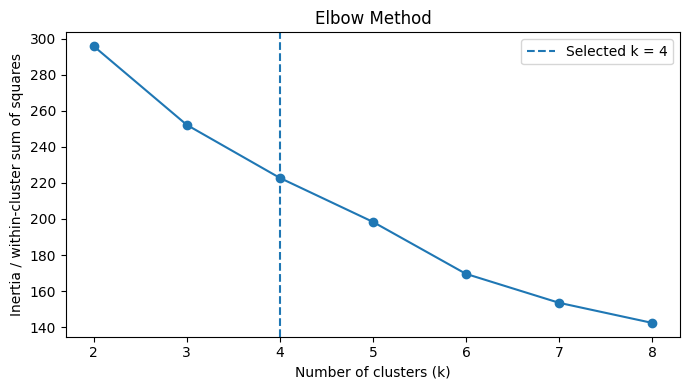

In [ ]:
plt.figure(figsize=(7, 4))
plt.plot(scores["k"], scores["inertia"], marker="o")
plt.axvline(RECOMMENDED_K, linestyle="--", label=f"Selected k = {RECOMMENDED_K}")
plt.xlabel("Number of clusters (k)")
plt.ylabel("Inertia / within-cluster sum of squares")
plt.title("Elbow Method")
plt.xticks(scores["k"])
plt.legend()
plt.tight_layout()
plt.show()

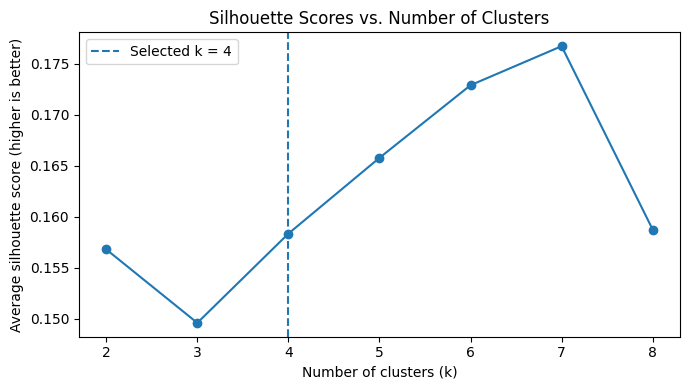

In [ ]:
plt.figure(figsize=(7, 4))
plt.plot(scores["k"], scores["silhouette"], marker="o")
plt.axvline(RECOMMENDED_K, linestyle="--", label=f"Selected k = {RECOMMENDED_K}")
plt.xlabel("Number of clusters (k)")
plt.ylabel("Average silhouette score (higher is better)")
plt.title("Silhouette Scores vs. Number of Clusters")
plt.xticks(scores["k"])
plt.legend()
plt.tight_layout()
plt.show()

## 5. Fit K-Means with the selected k

The raw cluster numbers output by K-Means are arbitrary. For **this 4-cluster dataset**, we relabel them in an easy-to-explain order based on cluster averages: (1) highest insurance premium, (2) highest alcohol involvement among remaining groups, (3) highest insurance loss among remaining groups, (4) remaining mixed-risk group.

In [ ]:
model = KMeans(n_clusters=RECOMMENDED_K, random_state=RANDOM_STATE, n_init=30)
df["raw_cluster"] = model.fit_predict(X)

# This case study is designed for the observed, selected four-group solution.
# For changed datasets with a different selected k, use generic labels.
if RECOMMENDED_K == 4:
    centers = df.groupby("raw_cluster")[FEATURES].mean()
    remaining = set(centers.index)
    premium_group = centers["premium_usd"].idxmax()
    remaining.remove(premium_group)
    alcohol_group = centers.loc[sorted(remaining), "alcohol_pct"].idxmax()
    remaining.remove(alcohol_group)
    loss_group = centers.loc[sorted(remaining), "loss_usd"].idxmax()
    remaining.remove(loss_group)
    mixed_group = remaining.pop()
    label_map = {
        premium_group: "Group 1 — High premiums / lower fatal-collision rate",
        alcohol_group: "Group 2 — Speeding and alcohol risks",
        loss_group: "Group 3 — High crash involvement and costs",
        mixed_group: "Group 4 — Mixed risks / lower speeding",
    }
else:
    label_map = {idx: f"Group {i+1}" for i, idx in enumerate(sorted(df["raw_cluster"].unique()))}

df["group"] = df["raw_cluster"].map(label_map)
print("Number of jurisdictions per group:")
display(df["group"].value_counts().sort_index().rename("Jurisdictions").to_frame())
print("Overall silhouette:", round(silhouette_score(X, df["raw_cluster"]), 3))

Number of jurisdictions per group:


,Jurisdictions
group,
Group 1 — High premiums / lower fatal-collision rate,7
Group 2 — Speeding and alcohol risks,13
Group 3 — High crash involvement and costs,12
Group 4 — Mixed risks / lower speeding,19


Overall silhouette: 0.158


## 6. Describe and compare the clusters

The table compares **group averages** with the overall averages. Higher `fatal_rate` = more drivers involved in fatal collisions per billion miles; speeding/alcohol percentages are among drivers involved in fatal collisions; costs are USD.

In [ ]:
profile = df.groupby("group", sort=True)[FEATURES].mean()
counts = df.groupby("group", sort=True).size().rename("n_jurisdictions")
profile_table = pd.concat([counts, profile], axis=1)

print("Group profiles (means):")
display(profile_table.round(1))
print("Overall 51-jurisdiction averages:")
display(df[FEATURES].mean().round(1).to_frame("Overall average").T)

print("All jurisdictions by group:")
for group, sub in df.sort_values("State").groupby("group", sort=True):
    print(f"\n{group} ({len(sub)} jurisdictions)")
    print(", ".join(sub["State"].tolist()))

print("\nState-level assignment table:")
display(df[["State", "group"] + FEATURES].sort_values(["group", "State"]).round(1))

Group profiles (means):


,n_jurisdictions,fatal_rate,speeding_pct,alcohol_pct,distracted_pct,prior_accidents_pct,premium_usd,loss_usd
group,,,,,,,,
Group 1 — High premiums / lower fatal-collision rate,7,10.5,29.9,31.6,9.3,17.7,1164.2,149.9
Group 2 — Speeding and alcohol risks,13,17.4,37.8,35.0,9.5,15.8,766.5,117.7
Group 3 — High crash involvement and costs,12,17.2,36.1,30.8,10.9,6.3,1014.8,158.6
Group 4 — Mixed risks / lower speeding,19,15.7,25.5,27.4,21.0,8.9,786.5,125.1


Overall 51-jurisdiction averages:


,fatal_rate,speeding_pct,alcohol_pct,distracted_pct,prior_accidents_pct,premium_usd,loss_usd
Overall average,15.8,31.7,30.7,14.1,11.3,887.0,134.5


All jurisdictions by group:

Group 1 — High premiums / lower fatal-collision rate (7 jurisdictions)
Connecticut, District of Columbia, Massachusetts, Michigan, New Jersey, New York, Rhode Island

Group 2 — Speeding and alcohol risks (13 jurisdictions)
Alabama, Hawaii, Maine, Missouri, Montana, New Hampshire, North Carolina, North Dakota, Ohio, South Carolina, South Dakota, Washington, Wyoming

Group 3 — High crash involvement and costs (12 jurisdictions)
Alaska, California, Delaware, Florida, Illinois, Louisiana, Maryland, Nevada, Oklahoma, Pennsylvania, Texas, West Virginia

Group 4 — Mixed risks / lower speeding (19 jurisdictions)
Arizona, Arkansas, Colorado, Georgia, Idaho, Indiana, Iowa, Kansas, Kentucky, Minnesota, Mississippi, Nebraska, New Mexico, Oregon, Tennessee, Utah, Vermont, Virginia, Wisconsin

State-level assignment table:


,State,group,fatal_rate,speeding_pct,alcohol_pct,distracted_pct,prior_accidents_pct,premium_usd,loss_usd
6,Connecticut,Group 1 — High premiums / lower fatal-collisio...,10.8,46,36,13,18,1068.7,167.0
8,District of Columbia,Group 1 — High premiums / lower fatal-collisio...,5.9,34,27,0,0,1273.9,136.0
21,Massachusetts,Group 1 — High premiums / lower fatal-collisio...,8.2,23,35,13,20,1011.1,135.6
22,Michigan,Group 1 — High premiums / lower fatal-collisio...,14.1,24,28,5,23,1110.6,152.3
30,New Jersey,Group 1 — High premiums / lower fatal-collisio...,11.2,16,28,14,22,1301.5,159.8
32,New York,Group 1 — High premiums / lower fatal-collisio...,12.3,32,29,12,20,1234.3,150.0
39,Rhode Island,Group 1 — High premiums / lower fatal-collisio...,11.1,34,38,8,21,1149.0,148.6
0,Alabama,Group 2 — Speeding and alcohol risks,18.8,39,30,4,20,784.6,145.1
11,Hawaii,Group 2 — Speeding and alcohol risks,17.5,54,41,18,13,861.2,120.9
19,Maine,Group 2 — Speeding and alcohol risks,15.1,38,30,13,16,661.9,96.6


## 7. Visualize clusters using PCA (2D illustration only)

PCA projects the **seven scaled features** into two axes to help visualize the groups. **Clustering is performed on all seven scaled features, not on these two PCA coordinates.** Overlapping projected groups do not mean the K-Means computation failed.

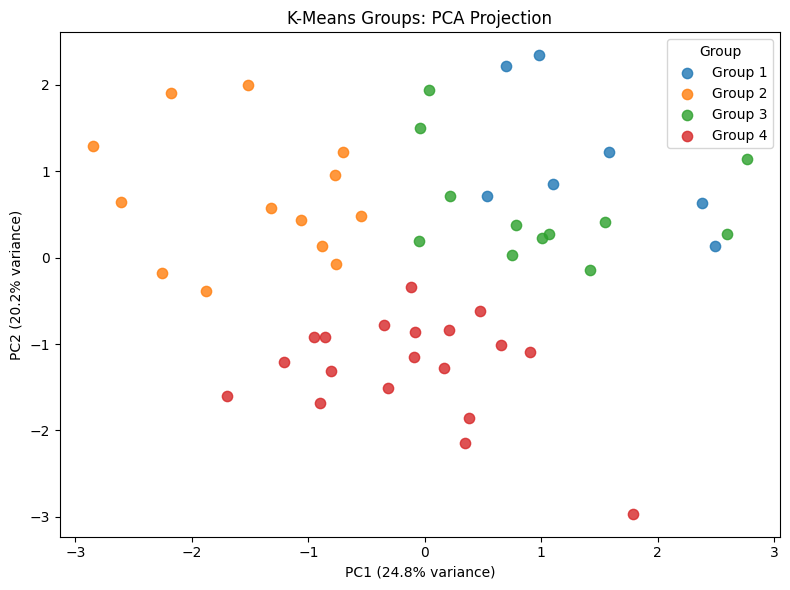

In [ ]:
pca = PCA(n_components=2, random_state=RANDOM_STATE)
coords = pca.fit_transform(X)
plt.figure(figsize=(8, 6))
for group in sorted(df["group"].unique()):
    mask = df["group"] == group
    plt.scatter(coords[mask, 0], coords[mask, 1], s=55, alpha=0.8,
                label=group.split(" — ")[0])
plt.xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.1%} variance)")
plt.ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.1%} variance)")
plt.title("K-Means Groups: PCA Projection")
plt.legend(title="Group", loc="best")
plt.tight_layout()
plt.show()

## 8. Compare cluster features to the national average

The heatmap shows how many standard deviations each group average is **above or below the 51-jurisdiction average**. The two complemented variables (`distracted_pct`, `prior_accidents_pct`) point toward potential risk when higher; insurance costs are *financial measures*, not direct measures of safety.

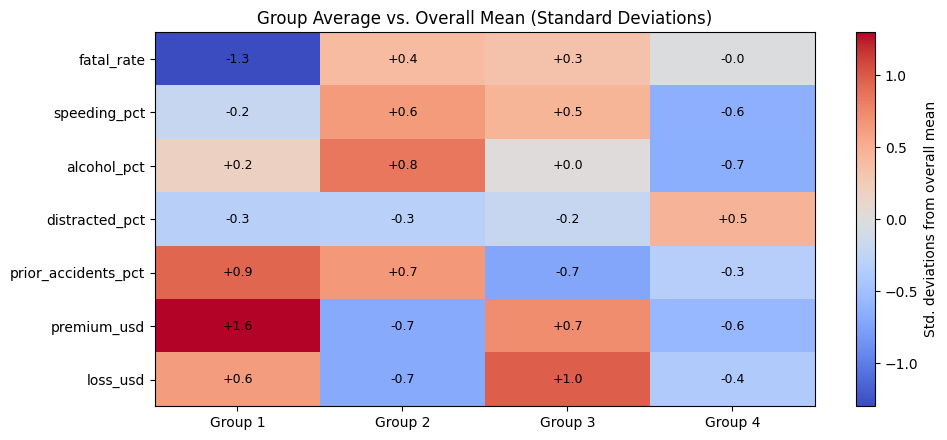

In [ ]:
relative = (profile - df[FEATURES].mean()) / df[FEATURES].std(ddof=0)
fig, ax = plt.subplots(figsize=(10, 4.5))
heat = ax.imshow(relative.T.values, aspect="auto", cmap="coolwarm", vmin=-1.3, vmax=1.3)
ax.set_xticks(range(len(relative.index)), [s.split(" — ")[0] for s in relative.index])
ax.set_yticks(range(len(FEATURES)), FEATURES)
ax.set_title("Group Average vs. Overall Mean (Standard Deviations)")
for i in range(len(FEATURES)):
    for j in range(len(relative.index)):
        ax.text(j, i, f"{relative.iloc[j, i]:+.1f}", ha="center", va="center", fontsize=9)
fig.colorbar(heat, ax=ax, label="Std. deviations from overall mean")
plt.tight_layout()
plt.show()

## 9. Recommend **one main campaign** per group

Each campaign is a **single program theme**, even if it involves multiple coordinated activities. Campaign labels are exploratory: cluster averages should not be applied to every state indiscriminately, and premium differences do not prove unsafe driving. The mixed-risk group should not automatically receive a distracted-driving campaign, because a few unusually high observations strongly affect the reported percentage.

In [ ]:
if RECOMMENDED_K == 4:
    campaign_map = {
        label_map[premium_group]: (
            "Defensive-driving / repeat-crash-awareness program. "
            "Validate the prior-accident signal and investigate non-driving causes of high premiums."
        ),
        label_map[alcohol_group]: (
            "High-risk driving prevention program targeting speeding and alcohol impairment "
            "through coordinated enforcement and education."
        ),
        label_map[loss_group]: (
            "Severe-crash prevention program targeting dangerous speeds and high-risk roads."
        ),
        label_map[mixed_group]: (
            "General road-safety awareness program with state-specific diagnosis. "
            "Only prioritize distracted driving after confirming local evidence."
        ),
    }
else:
    campaign_map = {
        group: "Targeted road-safety program after reviewing the group's local risk indicators."
        for group in df["group"].unique()
    }

campaigns = pd.DataFrame({
    "Number of jurisdictions": counts,
    "One primary campaign": pd.Series(campaign_map),
}).sort_index()
print("Campaign recommendation by group:")
display(campaigns)

# Report both mean and median because very high values can distort averages.
print("Inferred distraction percentage by group (mean vs median):")
display(df.groupby("group")["distracted_pct"].agg(["count", "mean", "median", "max"]).round(1))
print("Highest inferred distraction percentages:")
display(df[["State", "group", "distracted_pct"]]
        .sort_values("distracted_pct", ascending=False).head(6))

Campaign recommendation by group:


,Number of jurisdictions,One primary campaign
Group 1 — High premiums / lower fatal-collision rate,7,Defensive-driving / repeat-crash-awareness pro...
Group 2 — Speeding and alcohol risks,13,High-risk driving prevention program targeting...
Group 3 — High crash involvement and costs,12,Severe-crash prevention program targeting dang...
Group 4 — Mixed risks / lower speeding,19,General road-safety awareness program with sta...


Inferred distraction percentage by group (mean vs median):


,count,mean,median,max
group,,,,
Group 1 — High premiums / lower fatal-collision rate,7,9.3,12.0,14
Group 2 — Speeding and alcohol risks,13,9.5,8.0,19
Group 3 — High crash involvement and costs,12,10.9,8.5,29
Group 4 — Mixed risks / lower speeding,19,21.0,15.0,90


Highest inferred distraction percentages:


,State,group,distracted_pct
24,Mississippi,Group 4 — Mixed risks / lower speeding,90
49,Wisconsin,Group 4 — Mixed risks / lower speeding,61
37,Oregon,Group 4 — Mixed risks / lower speeding,33
31,New Mexico,Group 4 — Mixed risks / lower speeding,33
20,Maryland,Group 3 — High crash involvement and costs,29
18,Louisiana,Group 3 — High crash involvement and costs,27


## 10. Audit and sensitivity checks

**Interpretation safeguards:**

1. The highest silhouette score over **all** tested values is *not* at `k = 4`; four was chosen **only after** applying the minimum-five-jurisdictions planning rule. This is a subjective constraint, justified by the agency's need for campaigns with meaningful scope.
2. A silhouette score near `0.16` implies substantial overlap. Small differences, including the score gap between `k = 2` and `k = 4`, are not strong evidence for an exact number of groups.
3. The dataset contains outlying values for the complement of "not distracted" (particularly Mississippi and Wisconsin). Treat these figures as reported measures, **not definitive evidence** of actual distraction rates, and avoid equating high costs with driver risk.
4. The comparisons below assess **sensitivity**, not model accuracy. There is no labeled ground truth for these clusters. Adjusted Rand Index (ARI) compares agreement with the baseline clustering, with 1 denoting identical partitions and approximately 0 indicating chance-level agreement.

In [ ]:
from sklearn.metrics import adjusted_rand_score

base_labels = df["raw_cluster"].to_numpy()

def alternative_fit(frame, feature_set):
    X_alt = StandardScaler().fit_transform(frame[feature_set])
    labels_alt = KMeans(n_clusters=RECOMMENDED_K, random_state=RANDOM_STATE, n_init=30).fit_predict(X_alt)
    baseline_aligned = df.loc[frame.index, "raw_cluster"]
    return {
        "ARI vs original": adjusted_rand_score(baseline_aligned, labels_alt),
        "Silhouette": silhouette_score(X_alt, labels_alt),
        "Smallest cluster": int(pd.Series(labels_alt).value_counts().min()),
    }

cases = {
    "Seven-feature baseline": alternative_fit(df, FEATURES),
    "Exclude inferred distraction feature": alternative_fit(df, [f for f in FEATURES if f != "distracted_pct"]),
    "Five risk-only features (exclude insurance costs)": alternative_fit(df, FEATURES[:5]),
    "Exclude two distraction outlier states": alternative_fit(
        df.loc[~df["State"].isin(["Mississippi", "Wisconsin"])], FEATURES
    ),
}
print("Sensitivity tests (fixed k, same fitting rules):")
display(pd.DataFrame.from_dict(cases, orient="index").round(3))

# Explicitly check the extrapolation from a high group mean to a group-wide campaign.
if RECOMMENDED_K == 4:
    mixed = df.loc[df["raw_cluster"] == mixed_group]
    trimmed = mixed.loc[~mixed["State"].isin(["Mississippi", "Wisconsin"])]
    print("\nMixed-risk group: inferred distraction distribution")
    print(f"Mean = {mixed['distracted_pct'].mean():.1f}%, "
          f"median = {mixed['distracted_pct'].median():.1f}%, "
          f"mean excluding Mississippi and Wisconsin = {trimmed['distracted_pct'].mean():.1f}%")

print("\nCaution: an ARI well below 1 indicates feature and outlier sensitivity; "
      "the clusters are exploratory planning suggestions, not confirmed natural categories.")

Sensitivity tests (fixed k, same fitting rules):


,ARI vs original,Silhouette,Smallest cluster
Seven-feature baseline,1.000,0.158,7
Exclude inferred distraction feature,0.794,0.199,6
Five risk-only features (exclude insurance costs),0.256,0.219,2
Exclude two distraction outlier states,0.697,0.167,6



Mixed-risk group: inferred distraction distribution
Mean = 21.0%, median = 15.0%, mean excluding Mississippi and Wisconsin = 14.6%

Caution: an ARI well below 1 indicates feature and outlier sensitivity; the clusters are exploratory planning suggestions, not confirmed natural categories.


## 11. Conclusion

I used K-Means to group 51 U.S. jurisdictions based on driving risks and insurance costs. I chose four clusters because they gave a reasonable balance between the silhouette score and having at least five jurisdictions in every group. Group 1 has higher insurance premiums but lower fatal-collision involvement, so I would focus on defensive driving. Group 2 shows more speeding and alcohol impairment, so a risky-driving prevention campaign would fit. Group 3 has higher fatal-collision involvement and insurance losses, so it needs a serious-crash prevention campaign. Group 4 has mixed risks and lower speeding, so general road-safety education would be more appropriate. Since the silhouette score is only about 0.16, these groups are not very distinct, but they provide a useful starting point for campaign planning.